### Setup: imports and settings

In [1]:
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, KFold, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
DATA_DIR = Path.cwd() / "lab13_data"
DATA_DIR.mkdir(exist_ok=True)
pd.set_option("display.width", 120)
print("scikit-learn", sklearn.__version__, "| data directory: ./lab13_data/")


def check(description, condition):
    print(("PASS  " if condition else "CHECK ") + description)

scikit-learn 1.7.2 | data directory: ./lab13_data/


### Setup: UCI Heart Disease data

In [2]:
# ---- UCI Heart Disease: four hospitals --------------------------------------------------
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/"
SITE_FILES = {"Cleveland": "processed.cleveland.data", "Budapest": "processed.hungarian.data",
              "Zurich": "processed.switzerland.data", "Long Beach": "processed.va.data"}
UCI_COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
               "exang", "oldpeak", "slope", "ca", "thal", "num"]
EXPECTED_ROWS = {"Cleveland": 303, "Budapest": 294, "Zurich": 123, "Long Beach": 200}

SITES = {}
for site, fname in SITE_FILES.items():
    path = DATA_DIR / fname
    if not path.exists():
        urllib.request.urlretrieve(UCI_URL + fname, path)
    df = pd.read_csv(path, header=None, names=UCI_COLUMNS, na_values="?")
    df["target"] = (df["num"] > 0).astype(int)        # 0 = no disease, 1-4 = disease present
    SITES[site] = df
    check(f"{site}: {len(df)} patients (expected {EXPECTED_ROWS[site]})", len(df) == EXPECTED_ROWS[site])

PASS  Cleveland: 303 patients (expected 303)
PASS  Budapest: 294 patients (expected 294)
PASS  Zurich: 123 patients (expected 123)
PASS  Long Beach: 200 patients (expected 200)


### Setup: synthetic clinic visits

In [3]:
# ---- Synthetic clinic visits (hand-written generator; fictional patients) ---------------
def make_visits(seed=13, n_patients=500):
    """Each patient enrols on a random date and has 3-12 visits within the next two years.
    The 90-day admission label is drawn from a logistic model of the TRUE values, plus a
    patient-level 'frailty' that is never recorded. Visits end on 2024-09-30 so every visit
    has 90 days of follow-up. Planted features are documented in Part 2."""
    rng = np.random.default_rng(seed)
    start, last_visit = pd.Timestamp("2021-01-01"), pd.Timestamp("2024-09-30")
    span = (last_visit - start).days
    rows = []
    for pid in range(1, n_patients + 1):
        frailty = rng.normal()                       # unrecorded patient-level risk
        height = rng.normal(165, 9)
        weight0 = rng.normal(72, 13)
        age0 = rng.integers(40, 86)
        sbp0 = rng.normal(132, 15) + 4 * frailty
        hba1c0 = rng.normal(6.4, 1.0) + 0.3 * frailty
        enrol = int(rng.integers(0, span - 180))
        window = min(730, span - enrol)
        days = enrol + np.sort(rng.choice(window, rng.integers(3, 13), replace=False))
        for d in days:
            date = start + pd.Timedelta(days=int(d))
            new_device = date >= pd.Timestamp("2023-07-01")
            sbp_true = sbp0 + rng.normal(0, 8)
            sbp_recorded = sbp_true + (12 if new_device else 0)
            hba1c = hba1c0 + rng.normal(0, 0.3)
            age = age0 + d / 365.25
            log_odds = (-2.3 + 0.04 * (age - 65) + 0.025 * (sbp_true - 130)
                        + 0.45 * (hba1c - 6.4) + 2.0 * frailty)
            rows.append({"patient_id": f"P{pid:04d}", "visit_date": date.date().isoformat(),
                         "age": round(age, 1), "height_cm": round(height, 1),
                         "weight_kg": round(weight0 + rng.normal(0, 1.5), 1),
                         "systolic_bp": round(sbp_recorded), "hba1c_pct": round(hba1c, 1),
                         "admitted_90d": int(rng.random() < 1 / (1 + np.exp(-log_odds)))})
    return pd.DataFrame(rows)


visits = make_visits()
visits.to_csv(DATA_DIR / "synthetic_visits.csv", index=False)
visits["visit_date"] = pd.to_datetime(visits["visit_date"])
FEATURES = ["age", "height_cm", "weight_kg", "systolic_bp", "hba1c_pct"]
visits.head()

,patient_id,visit_date,age,height_cm,weight_kg,systolic_bp,hba1c_pct,admitted_90d
0,P0001,2021-11-08,83.9,137.3,81.7,155,7.2,1
1,P0001,2022-02-11,84.1,137.3,85.1,157,7.7,1
2,P0001,2022-06-03,84.4,137.3,86.7,171,7.4,1
3,P0001,2023-01-24,85.1,137.3,85.0,169,6.9,1
4,P0001,2023-05-31,85.4,137.3,83.2,161,7.2,1


### Exercise 1.1: What is a row?

In [4]:
n_rows = len(visits)
n_patients = visits["patient_id"].nunique()
visits_per_patient = visits.groupby("patient_id").size()
admission_rate = visits["admitted_90d"].mean()

print("rows (visits):", n_rows, "| patients:", n_patients)
if visits_per_patient is not None:
    print("visits per patient: min", visits_per_patient.min(), "median", visits_per_patient.median(),
          "max", visits_per_patient.max())
print("admission rate per visit:", admission_rate)
check("500 patients", n_patients == 500)
check("more rows than patients", n_rows is not None and n_rows > 500)

rows (visits): 3748 | patients: 500
visits per patient: min 3 median 8.0 max 12
admission rate per visit: 0.24733191035218782
PASS  500 patients
PASS  more rows than patients


### Exercise 1.1: Within-patient variation

In [5]:
per_patient = visits.groupby("patient_id")[["height_cm", "systolic_bp", "hba1c_pct"]].std().mean()
print("Average within-patient standard deviation across visits:")
print(per_patient.round(2))

Average within-patient standard deviation across visits:
height_cm      0.00
systolic_bp    8.47
hba1c_pct      0.28
dtype: float64


### Exercise 1.2: Row-level versus patient-level cross-validation

In [6]:
def make_logreg():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))


def make_forest():
    # min_samples_leaf=1 lets trees fit individual visits, which makes memorisation possible
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=1, random_state=0, n_jobs=-1)


def cv_auroc(model, cv, groups=None):
    p = cross_val_predict(model, visits[FEATURES], visits["admitted_90d"], cv=cv, groups=groups,
                          method="predict_proba")[:, 1]
    return round(roc_auc_score(visits["admitted_90d"], p), 3)


row_cv = KFold(n_splits=5, shuffle=True, random_state=0)
patient_cv = GroupKFold(n_splits=5)

results_split = []
for name, make in [("logistic regression", make_logreg), ("random forest", make_forest)]:
    row = cv_auroc(make(), row_cv)
    patient = cv_auroc(make(), patient_cv, groups=visits["patient_id"])
    results_split.append({"model": name, "row-level CV AUROC": row, "patient-level CV AUROC": patient})

split_table = pd.DataFrame(results_split)
split_table

,model,row-level CV AUROC,patient-level CV AUROC
0,logistic regression,0.733,0.727
1,random forest,0.803,0.658


### Exercise 1.3 — Answer

The random forest's AUROC falls from 0.803 to 0.658 when we group visits by patient, a drop of 0.145, while logistic regression falls from 0.733 to 0.727, a drop of 0.006. The forest can use repeated combinations of features, including stable height, to recognize patients and learn their underlying admission tendency from other visits. Logistic regression assigns a single coefficient to each input, which limits its ability to learn patient-specific patterns. I would report the patient-level AUROC of 0.727 for logistic regression because it estimates performance on unseen patients. Selecting by row-level AUROC would have favored the forest even though it ranks new patients worse.

### Part 2: Temporal validation

In [7]:
train_mask = visits["visit_date"] < "2023-01-01"
test_mask = visits["visit_date"] >= "2024-01-01"
train, test = visits[train_mask], visits[test_mask]
seen_patients = set(train["patient_id"])
print(f"train: {len(train)} visits, {train['patient_id'].nunique()} patients | "
      f"test: {len(test)} visits, {test['patient_id'].nunique()} patients "
      f"({test['patient_id'].isin(seen_patients).mean():.0%} of test visits from patients also in training)")

temporal_model = make_logreg().fit(train[FEATURES], train["admitted_90d"])
p_temporal = temporal_model.predict_proba(test[FEATURES])[:, 1]
print("temporal test AUROC:", round(roc_auc_score(test["admitted_90d"], p_temporal), 3))

train: 1151 visits, 261 patients | test: 1307 visits, 309 patients (15% of test visits from patients also in training)
temporal test AUROC: 0.724


### Exercise 2.1: Calibration over time

training period: {'mean_predicted': 0.247, 'observed_rate': 0.247, 'observed_to_expected': 1.0}
test period:     {'mean_predicted': 0.328, 'observed_rate': 0.231, 'observed_to_expected': 0.7}


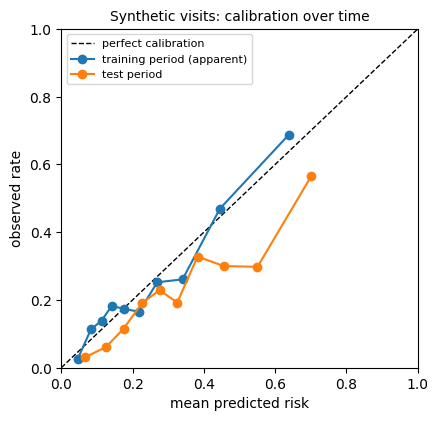

In [8]:
def calibration_in_the_large(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return {"mean_predicted": round(p.mean(), 3), "observed_rate": round(y.mean(), 3),
            "observed_to_expected": round(y.mean() / p.mean(), 2)}


def plot_reliability(curves, title, n_bins=10):
    """curves: dict label -> (y, p). Equal-count bins of predicted risk."""
    fig, ax = plt.subplots(figsize=(4.6, 4.4))
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
    for label, (y, p) in curves.items():
        frame = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
        frame["bin"] = pd.qcut(frame["p"], q=min(n_bins, len(frame) // 10 or 1), duplicates="drop")
        g = frame.groupby("bin", observed=True).agg(p=("p", "mean"), y=("y", "mean"))
        ax.plot(g["p"], g["y"], "o-", label=label)
    ax.set_xlabel("mean predicted risk"); ax.set_ylabel("observed rate")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.set_title(title, fontsize=10)
    plt.show()


p_train_fit = temporal_model.predict_proba(train[FEATURES])[:, 1]
print("training period:", calibration_in_the_large(train["admitted_90d"], p_train_fit))
print("test period:    ", calibration_in_the_large(test["admitted_90d"], p_temporal))
plot_reliability({"training period (apparent)": (train["admitted_90d"], p_train_fit),
                  "test period": (test["admitted_90d"], p_temporal)}, "Synthetic visits: calibration over time")

### Exercise 2.2: Find the cause

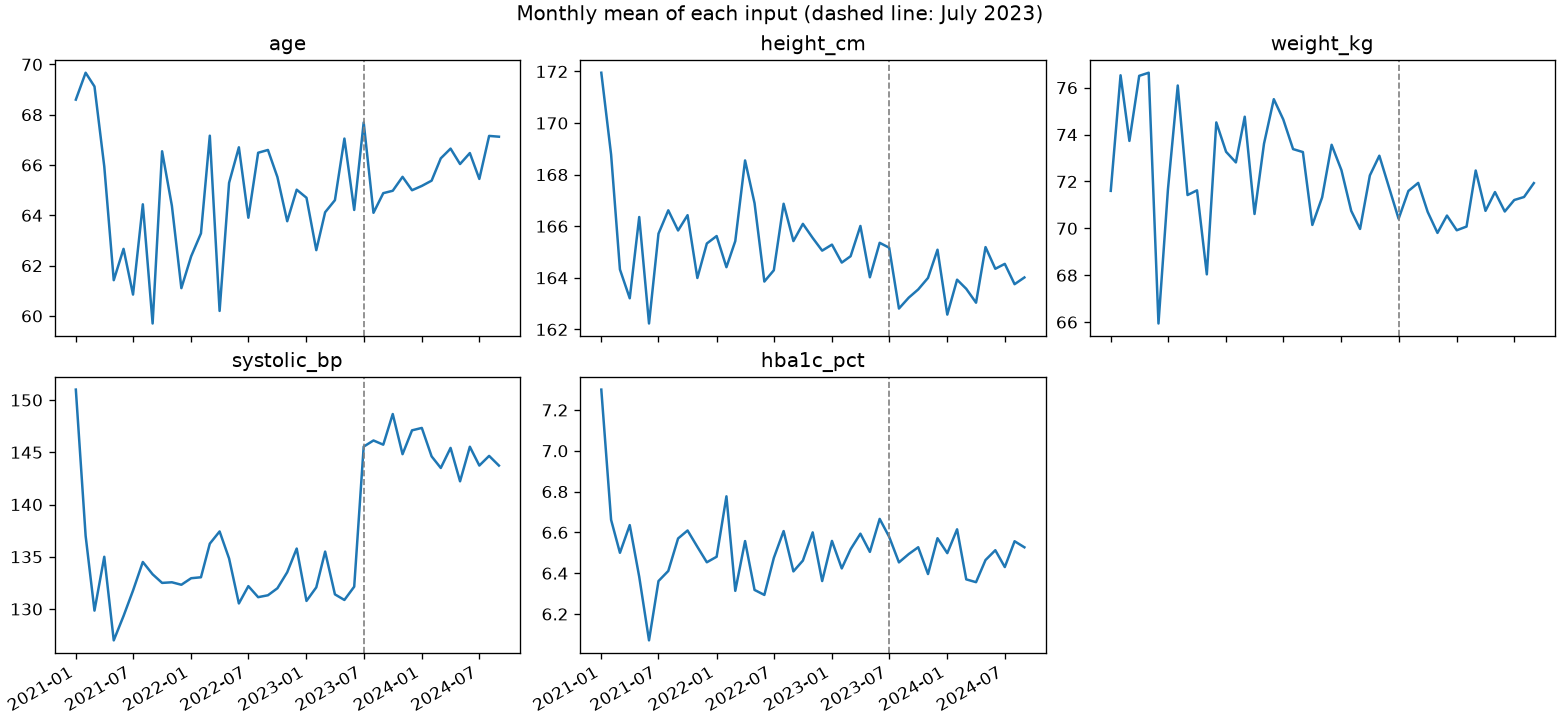

In [9]:
monthly_inputs = visits.set_index("visit_date")[FEATURES].resample("MS").mean()
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, layout="constrained")
for ax, col in zip(axes.flat, FEATURES):
    ax.plot(monthly_inputs[col])
    ax.axvline(pd.Timestamp("2023-07-01"), color="0.5", linestyle="--", linewidth=1)
    ax.set_title(col)
axes.flat[-1].set_visible(False)
fig.suptitle("Monthly mean of each input (dashed line: July 2023)")
fig.autofmt_xdate(rotation=30)
plt.show()

### Exercise 2.3 — Answer

Mean recorded systolic blood pressure rose from 132.1 mm Hg in June 2023 to 145.5 mm Hg in July, a jump of about 13.4 mm Hg that coincides with the new device adding 12 mm Hg to each reading. The model interpreted the higher readings as higher risk even though the device shift did not change the underlying risk, so mean predicted risk was 0.328 versus an observed rate of 0.231 (observed-to-expected ratio 0.70). Temporal test AUROC was still 0.724 because a constant shift in this input moves every patient's logistic score by the same amount, preserving the ranking. After deployment, I would track monthly input distributions by device and compare mean predicted risk with observed admissions once 90-day labels are available. I would measure the offset with paired readings from both devices, correct the readings, and check calibration on a later holdout.

### Part 3: External validation

In [10]:
CORE = ["age", "sex", "cp", "trestbps", "thalach", "exang", "oldpeak", "restecg"]


def design(df):
    """Core inputs, with chest-pain type and resting ECG one-hot encoded (reference levels dropped)."""
    x = df[CORE].copy()
    x[["cp", "restecg"]] = x[["cp", "restecg"]].astype(int)
    x = pd.get_dummies(x, columns=["cp", "restecg"], dtype=float)
    for col in ["cp_1", "cp_2", "cp_3", "cp_4", "restecg_0", "restecg_1", "restecg_2"]:
        if col not in x:
            x[col] = 0.0
    return x[sorted(x.columns)].drop(columns=["cp_1", "restecg_0"])


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half, centre + half)


def boot_auroc_ci(y, p, n_boot=1000):
    rng = np.random.default_rng(SEED)
    vals = [roc_auc_score(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))
            if 0 < y[i].sum() < len(i)]
    return np.percentile(vals, [2.5, 97.5])


def calibration_slope(y, p):
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    return LogisticRegression(penalty=None).fit(logit, y).coef_[0, 0]


def fmt(k, n):
    if n == 0:
        return "undefined"
    lo, hi = wilson(k, n)
    return f"{k}/{n} = {k / n:.2f} ({lo:.2f}-{hi:.2f})"


def validation_report(label, y, p, threshold=0.5):
    y, p = np.asarray(y), np.asarray(p)
    yhat = p >= threshold
    tp, fn = int((yhat & (y == 1)).sum()), int((~yhat & (y == 1)).sum())
    tn, fp = int((~yhat & (y == 0)).sum()), int((yhat & (y == 0)).sum())
    lo, hi = boot_auroc_ci(y, p)
    cal = calibration_in_the_large(y, p)
    return {"site": label, "n": len(y), "with disease": f"{int(y.sum())} ({y.mean():.0%})",
            "AUROC (95% CI)": f"{roc_auc_score(y, p):.2f} ({lo:.2f}-{hi:.2f})",
            "mean predicted": cal["mean_predicted"], "calibration slope": round(calibration_slope(y, p), 2),
            "sensitivity": fmt(tp, tp + fn), "specificity": fmt(tn, tn + fp),
            "PPV": fmt(tp, tp + fp), "NPV": fmt(tn, tn + fn)}


dev = SITES["Cleveland"]
heart_model = make_logreg().fit(design(dev), dev["target"])
p_internal = cross_val_predict(make_logreg(), design(dev), dev["target"],
                               cv=StratifiedKFold(10, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]

EXTERNAL = {}
reports = [validation_report("Cleveland (internal, 10-fold CV)", dev["target"], p_internal)]
for site in ["Budapest", "Zurich", "Long Beach"]:
    df = SITES[site]
    keep = df[CORE].notna().all(axis=1)
    print(f"{site}: excluded {int((~keep).sum())} of {len(df)} for missing core inputs")
    EXTERNAL[site] = df[keep].reset_index(drop=True)
    p = heart_model.predict_proba(design(EXTERNAL[site]))[:, 1]
    EXTERNAL[site]["p"] = p
    reports.append(validation_report(site, EXTERNAL[site]["target"], p))

external_table = pd.DataFrame(reports).set_index("site")
external_table.T

Budapest: excluded 2 of 294 for missing core inputs


Zurich: excluded 7 of 123 for missing core inputs


Long Beach: excluded 59 of 200 for missing core inputs


site,"Cleveland (internal, 10-fold CV)",Budapest,Zurich,Long Beach
n,303,292,116,141
with disease,139 (46%),105 (36%),108 (93%),111 (79%)
AUROC (95% CI),0.87 (0.84-0.91),0.88 (0.83-0.92),0.75 (0.59-0.91),0.72 (0.61-0.82)
mean predicted,0.459,0.41,0.684,0.796
calibration slope,0.88,0.89,0.54,0.48
sensitivity,104/139 = 0.75 (0.67-0.81),81/105 = 0.77 (0.68-0.84),83/108 = 0.77 (0.68-0.84),104/111 = 0.94 (0.88-0.97)
specificity,140/164 = 0.85 (0.79-0.90),156/187 = 0.83 (0.77-0.88),4/8 = 0.50 (0.22-0.78),8/30 = 0.27 (0.14-0.44)
PPV,104/128 = 0.81 (0.74-0.87),81/112 = 0.72 (0.63-0.80),83/87 = 0.95 (0.89-0.98),104/126 = 0.83 (0.75-0.88)
NPV,140/175 = 0.80 (0.73-0.85),156/180 = 0.87 (0.81-0.91),4/29 = 0.14 (0.05-0.31),8/15 = 0.53 (0.30-0.75)


### Part 3: Calibration by site

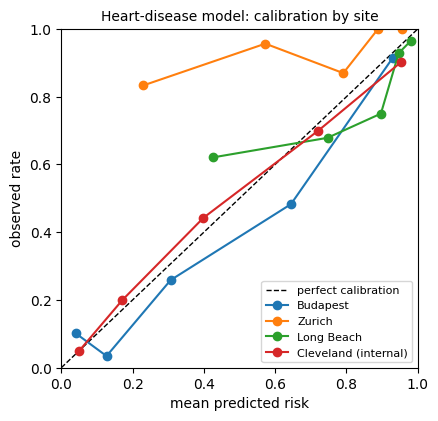

In [11]:
plot_reliability({site: (EXTERNAL[site]["target"], EXTERNAL[site]["p"]) for site in EXTERNAL}
                 | {"Cleveland (internal)": (dev["target"], p_internal)},
                 "Heart-disease model: calibration by site", n_bins=5)

### Exercise 3.1 — Answer

Budapest's AUROC of 0.88 (95% CI 0.83–0.92) is close to Cleveland's 0.87 (0.84–0.91), while Long Beach performs worse at 0.72 (0.61–0.82). Zurich's estimate is 0.75, with a wide interval of 0.59–0.91 that also includes Cleveland's estimate. Budapest mildly overpredicts on average (41% predicted versus 36% observed) and its slope of 0.89 suggests slightly too-extreme risks. Zurich substantially underpredicts (68% versus 93%) and its slope of 0.54 indicates predictions are too spread out. Long Beach slightly overpredicts on average (80% versus 79%), but a slope of 0.48 means the low and high predictions are too far apart even when the site average is close. Zurich's specificity of 4/8 is based on only eight patients without disease, so the 95% CI of 0.22–0.78 leaves considerable uncertainty. Long Beach excluded 59 of 200 patients, and the complete-case results could be biased if tests were missing more often in patients with different severity or diagnostic workups.

### Exercise 3.2: Recalibrate the model for Budapest

In [12]:
def logit(p):
    p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def fit_recalibration(y_fit, p_fit):
    model = LogisticRegression(penalty=None).fit(logit(p_fit), y_fit)
    return lambda p_new: model.predict_proba(logit(p_new))[:, 1]


bud = EXTERNAL["Budapest"]
fit_half, eval_half = train_test_split(bud, test_size=0.5, stratify=bud["target"], random_state=SEED)
recalibrate = fit_recalibration(fit_half["target"], fit_half["p"])
p_before, p_after = eval_half["p"].to_numpy(), recalibrate(eval_half["p"])

y_eval = eval_half["target"].to_numpy()
print("evaluation half, before:", calibration_in_the_large(y_eval, p_before),
      "| slope", round(calibration_slope(y_eval, p_before), 2), "| AUROC", round(roc_auc_score(y_eval, p_before), 3))
print("evaluation half, after: ", calibration_in_the_large(y_eval, p_after),
      "| slope", round(calibration_slope(y_eval, np.clip(p_after, 1e-6, 1 - 1e-6)), 2),
      "| AUROC", round(roc_auc_score(y_eval, p_after), 3))
check("recalibration changed the predictions", not np.allclose(p_before, p_after))

evaluation half, before: {'mean_predicted': 0.394, 'observed_rate': 0.356, 'observed_to_expected': 0.9} | slope 0.96 | AUROC 0.893
evaluation half, after:  {'mean_predicted': 0.335, 'observed_rate': 0.356, 'observed_to_expected': 1.06} | slope 1.16 | AUROC 0.893
PASS  recalibration changed the predictions


### Exercise 3.2: Answer

Mean predicted risk moved from 0.394 to 0.335 (observed 0.356), so slight overprediction became slight underprediction. The slope moved from 0.96 to 1.16, so it was not a clear improvement. AUROC stayed at 0.893 because the order of patients did not change. With 146 patients the fit is noisy and can overcorrect, so I would require more local data and a prospective evaluation.

### Exercise 4.1: Performance by sex

In [13]:
def subgroup_table(df, y_col, p_col, group_col, threshold=0.5):
    rows = []
    for value, g in df.groupby(group_col):
        y, p = g[y_col].to_numpy(), g[p_col].to_numpy()
        yhat = p >= threshold
        tp, fn = int((yhat & (y == 1)).sum()), int((~yhat & (y == 1)).sum())
        tn, fp = int((~yhat & (y == 0)).sum()), int((yhat & (y == 0)).sum())
        rows.append({"group": value, "n": len(g), "with disease": int(y.sum()),
                     "AUROC": round(roc_auc_score(y, p), 3),
                     "sensitivity": fmt(tp, tp + fn), "specificity": fmt(tn, tn + fp)})
    return pd.DataFrame(rows)


SEX = {0: "women", 1: "men"}
cle = dev.assign(p=p_internal, group=dev["sex"].map(SEX))
display(subgroup_table(cle, "target", "p", "group").assign(site="Cleveland (internal)"))
display(subgroup_table(EXTERNAL["Budapest"].assign(group=EXTERNAL["Budapest"]["sex"].map(SEX)),
                       "target", "p", "group").assign(site="Budapest"))

,group,n,with disease,AUROC,sensitivity,specificity,site
0,men,206,114,0.842,86/114 = 0.75 (0.67-0.82),72/92 = 0.78 (0.69-0.85),Cleveland (internal)
1,women,97,25,0.894,18/25 = 0.72 (0.52-0.86),68/72 = 0.94 (0.87-0.98),Cleveland (internal)


,group,n,with disease,AUROC,sensitivity,specificity,site
0,men,212,93,0.877,75/93 = 0.81 (0.71-0.87),93/119 = 0.78 (0.70-0.85),Budapest
1,women,80,12,0.784,6/12 = 0.50 (0.25-0.75),63/68 = 0.93 (0.84-0.97),Budapest


### Exercise 4.1 — Answer

Cleveland shows similar sensitivity in women (0.72, 18/25) and men (0.75, 86/114). Budapest shows a concerning gap, with sensitivity of 0.50 (6/12) in women and 0.81 (75/93) in men. Only 25 women in Cleveland and 12 in Budapest had disease, so the sensitivity estimates for women are imprecise. Equal sensitivity matters most here because a false negative could delay referral for a patient with disease. These data flag a disparity worth investigating in Budapest, and a larger validation sample is needed to estimate the gap reliably.

### Exercise 4.2: Chest-pain type by error group

In [14]:
bud = EXTERNAL["Budapest"].copy()
bud["error"] = np.select([(bud["target"] == 1) & (bud["p"] < 0.5), (bud["target"] == 0) & (bud["p"] >= 0.5)],
                         ["false negative", "false positive"], default="correct")
print(bud["error"].value_counts())

cp_by_error = pd.crosstab(bud["error"], bud["cp"], normalize="index", margins=True).round(2)
cp_by_error

error
correct           237
false positive     31
false negative     24
Name: count, dtype: int64


cp,1,2,3,4
error,,,,
correct,0.03,0.42,0.17,0.38
false negative,0.12,0.12,0.42,0.33
false positive,0.00,0.10,0.10,0.81
All,0.03,0.36,0.18,0.42


### Exercise 4.2 — All false negatives and false positives

In [15]:
cols = CORE + ["target", "p"]
for error_type in ("false negative", "false positive"):
    cases = bud.loc[bud["error"].eq(error_type), cols].sort_values(
        "p", ascending=error_type == "false negative"
    )
    print(f"{len(cases)} {error_type} cases (index: Budapest validation row)")
    with pd.option_context("display.max_rows", None, "display.precision", 4):
        display(cases)

24 false negative cases (index: Budapest validation row)


,age,sex,cp,trestbps,thalach,exang,oldpeak,restecg,target,p
255,47,0,3,135.0,170.0,0.0,0.0,0.0,1,0.0167
189,34,1,1,140.0,180.0,0.0,0.0,0.0,1,0.0464
209,49,1,3,115.0,175.0,0.0,0.0,0.0,1,0.0583
208,49,0,3,160.0,156.0,0.0,1.0,0.0,1,0.0654
269,56,0,2,120.0,150.0,0.0,1.0,0.0,1,0.0724
211,50,0,3,140.0,140.0,1.0,0.0,0.0,1,0.0786
228,43,1,1,120.0,155.0,0.0,0.0,1.0,1,0.1012
190,35,1,2,110.0,140.0,0.0,0.0,0.0,1,0.1197
254,46,1,1,140.0,175.0,0.0,2.0,0.0,1,0.2092
288,54,0,3,130.0,100.0,1.0,0.0,1.0,1,0.2213


31 false positive cases (index: Budapest validation row)


,age,sex,cp,trestbps,thalach,exang,oldpeak,restecg,target,p
136,53,1,4,124.0,112.0,1.0,3.0,1.0,0,0.9802
164,55,1,4,140.0,110.0,1.0,0.5,0.0,0,0.9061
184,61,1,4,125.0,115.0,1.0,0.0,1.0,0,0.8954
154,54,1,4,150.0,134.0,0.0,1.0,1.0,0,0.8599
84,46,1,4,180.0,120.0,0.0,0.0,1.0,0,0.8557
82,46,1,4,110.0,140.0,1.0,1.0,1.0,0,0.8329
171,57,0,4,180.0,126.0,1.0,0.8,1.0,0,0.8265
89,47,1,4,140.0,125.0,1.0,0.0,0.0,0,0.8050
176,58,1,4,135.0,100.0,0.0,0.0,0.0,0,0.7942
114,50,1,4,150.0,140.0,1.0,0.0,0.0,0,0.7927


### Exercise 4.2: Inputs by error group and model coefficients

In [16]:
display(bud.groupby("error")[["age", "sex", "exang", "oldpeak", "thalach"]].mean().round(2))
pd.Series(heart_model[-1].coef_[0], design(dev).columns).round(2)

,age,sex,exang,oldpeak,thalach
error,,,,,
correct,47.48,0.71,0.30,0.60,139.37
false negative,45.17,0.75,0.21,0.52,153.00
false positive,52.29,0.84,0.42,0.48,126.65


age          0.23
cp_2         0.24
cp_3         0.08
cp_4         1.06
exang        0.38
oldpeak      0.74
restecg_1    0.05
restecg_2    0.25
sex          0.79
thalach     -0.49
trestbps     0.30
dtype: float64

### Exercise 4.2 — Answer

Non-anginal pain was more common among the 24 false negatives (42%) than across all Budapest patients (18%). Among the 31 false positives, 81% were coded as asymptomatic. This matches the Session 5 observation about chest pain: the asymptomatic category has the largest positive standardized coefficient in the Cleveland model (+1.06, with typical angina as the reference), so that category raises the score given the other inputs. False negatives also had a higher mean maximum heart rate than correctly classified cases (153 versus 139 bpm). I would collect more representative cases before changing the intended use and keep the score limited to referral support, with clinical review of low scores.

### Part 5 — Validation report

**Model and intended use**  
Logistic regression uses eight routine inputs to estimate coronary disease risk and support referral decisions.

**Development data**  
Cleveland contributed 303 evaluated patients, of whom 139 (46%) had disease (UCI outcome codes 1–4). Collection dates were unavailable in the processed data.

**Validation performed**  
Cleveland used stratified 10-fold cross-validation. The Cleveland-fitted model was tested at Budapest, Zurich, and Long Beach after excluding 2/294, 7/123, and 59/200 patients with missing inputs, respectively.

**Discrimination and calibration**  
AUROC (95% CI) was 0.87 (0.84–0.91) in Cleveland, 0.88 (0.83–0.92) in Budapest, 0.75 (0.59–0.91) in Zurich, and 0.72 (0.61–0.82) in Long Beach. Budapest overpredicted on average. Zurich underpredicted, and its slope of 0.54 and Long Beach's slope of 0.48 indicate overly dispersed risks.

**Threshold performance**  
At 0.5, sensitivity/specificity were 0.75/0.85 in Cleveland, 0.77/0.83 in Budapest, 0.77/0.50 in Zurich, and 0.94/0.27 in Long Beach. Zurich's specificity used eight patients without disease.

**Subgroups**  
Budapest sensitivity was 6/12 in women and 75/93 in men. The small number of women with disease limits precision.

**Known failure modes and limitations**  
Non-anginal pain was common among Budapest false negatives. Missing inputs may have biased the Long Beach estimates.

**Recommendation**  
Defer clinical use until local calibration, threshold performance, and subgroup sensitivity are assessed in a larger prospective validation.

### Part 5: Reflection

Row-level splitting is the easiest mistake to miss, because the code runs normally and the higher score looks like good news. Here it made the worse model look best. My habit: first ask what one row is, and split by patient when patients repeat.